# Домашнее задание. Применение статистических критериев

В этом задании вы потренируетесь подбирать и применять статистические критерии под конкретную задачу: доверительные интервалы, одновыборочные и двухвыборочные тесты, дисперсионный анализ и анализ долей.

Инструкции:
- Скопируйте ноутбук себе и заполните ячейки с кодом и выводами.
- В каждой задаче приведите код, выведите на экран требуемые значения и добавьте краткий вывод (1-2 фразы) в текстовой ячейке.
- Там, где используется случайная генерация, фиксируйте np.random.seed для воспроизводимости.
- Разрешённые библиотеки: numpy, scipy, statsmodels, matplotlib.

Формат сдачи: файл .ipynb с заполненными ячейками. Перед отправкой перезапустите ноутбук от начала до конца, чтобы **вывод от кода был отображён**.

In [25]:
# ячейка с импортами - дополняйте по своему желанию
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.weightstats import CompareMeans, DescrStatsW
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.proportion import proportion_confint, proportions_ztest

### Задание 1. Сопоставление статистик

Для каждой ситуации укажите наиболее подходящий критерий из списка: z-тест, t-тест (объединённый), Welch t-тест, F-тест (сравнение дисперсий), критерий хи-квадрат (согласия), однофакторный ANOVA, Tukey HSD, критерий Левена.

**Ситуации:**
1. Нужно проверить, отличается ли средний объём дозы от заданного значения; дисперсия процесса известна.
2. Сравнить средние двух независимых групп при неизвестных, но равных дисперсиях.
3. Сравнить средние двух независимых групп при неизвестных и неравных дисперсиях.
4. Оценить, одинаковы ли средние в трёх и более группах.
5. Проверить, согласуются ли наблюдаемые частоты с распределением Пуассона.

**Что сделать:** для каждой ситуации кратко (1-2 предложения) обоснуйте выбор критерия в MarkDown-ячейке ниже.

**Вывод:** 
1. z-тест потому что мы знаем дисперсию, отличается ли среднее от заданного значения.

2. t-тест потому что сравниваем две независимые группы, у которых дисперсии неизвестны и равными.

3. Welch t-тест потому что сравниваем две независимые группы, у которых дисперсии неизвестны и **неравны**.

4. Однофакторный ANOVA, групп >= 3 и ищем разницу между их средними.

5. Критерий хи-квадрат согласия подходит, тк псравнивает частоты в одной выборке с теоретическим распределением.


### Задание 2. Тест для дозатора

Дозатор настроен на среднюю дозу 3.00 г. Получено $n = 50$ измерений со средним $\bar X = 3.005$ и известным стандартным отклонением процесса $\sigma = 0.015$.

**Что сделать:**
- проверьте гипотезу $H_0: \mu = 3.00$ при $\alpha = 0.05$;
- постройте 95% доверительный интервал для $\mu$;
- сделайте практический вывод в MarkDown-ячейке: нужно ли перенастраивать дозатор.

**Выведите на экран:** наблюдаемое значение статистики, p-value, границы доверительного интервала.

In [26]:
mu0, xbar, sigma, n = 3.00, 3.005, 0.015, 50

alpha = 0.05
stderror = sigma / np.sqrt(n)
z = (xbar - mu0) / stderror
print(f'z = {z}')
pvalue = 2 * stats.norm.sf(abs(z))
print(f'p-value = {pvalue}')
dovdown = xbar - stats.norm.ppf(1 - alpha / 2) * stderror
dovup = xbar + stats.norm.ppf(1 - alpha / 2) * stderror
print(f'95% доверительный интервал = ({dovdown}, {dovup})')

z = 2.3570226039551083
p-value = 0.018422125454101476
95% доверительный интервал = (3.000842288526951, 3.009157711473049)


**Вывод:** при уровне значимости 0.05 отвергаем гипотезу, что средняя доза равна 3г, так как p-value = 0.0184. 
Доверительный интервал тоже не включает дозу в 3г. Средняя доза 3.005г, дозатор нужно перенастроить.

### Задание 3. Сравнение прочности материалов

Даны две независимые выборки прочности материалов (в MPa):

A (n=15): 51.99, 49.45, 52.59, 56.09, 49.06, 49.06, 56.32, 53.07, 48.12, 52.17, 48.15, 48.14, 50.97, 42.35, 43.10

B (n=10): 48.63, 45.92, 53.89, 46.55, 43.53, 60.79, 50.65, 52.41, 43.45, 48.73

**Что сделать:**
- проверьте равенство дисперсий (критерий Левена и классический F-тест);
- в зависимости от результата примените объединённый t-тест или Welch t-тест для проверки $H_0: \mu_A = \mu_B$ при $\alpha = 0.05$;
- постройте 95% доверительный интервал для разности средних и интерпретируйте его.

Выведите на экран: p-value критерия Левена, F-статистику и p-value F-теста, статистику и p-value выбранного t-теста, разность средних и границы доверительного интервала.

In [27]:
A = np.array([51.99,49.45,52.59,56.09,49.06,49.06,56.32,53.07,48.12,52.17,48.15,48.14,50.97,42.35,43.10])
B = np.array([48.63,45.92,53.89,46.55,43.53,60.79,50.65,52.41,43.45,48.73])

alpha = 0.05
levene, levene_p = stats.levene(A, B)
print(f'Левен p-value = {levene_p}')
f = np.var(A, ddof=1) / np.var(B, ddof=1)
print(f'F = {f}')
step_svo_a = len(A) - 1
step_svo_b = len(B) - 1
f_p = 2 * min(stats.f.cdf(f, step_svo_a, step_svo_b),
              stats.f.sf(f, step_svo_a, step_svo_b))
print(f'F-тест p-value = {f_p}')
equal_var = levene_p >= alpha and f_p >= alpha
t, pvalue = stats.ttest_ind(A, B, equal_var=equal_var)
print(f't = {t:.4f}')
print(f't-тест p-value = {pvalue}')
difference = np.mean(A) - np.mean(B)
print(f'Разность средних = {difference}')
cm = CompareMeans(DescrStatsW(A), DescrStatsW(B))
dovdown, dovup = cm.tconfint_diff(
    alpha=alpha,
    usevar='pooled' if equal_var else 'unequal')
print(f'95% доверительный интервал = ({dovdown}, {dovup})')

Левен p-value = 0.5009261326774884
F = 0.5655641299130366
F-тест p-value = 0.32710529669178184
t = 0.3171
t-тест p-value = 0.7540512036025819
Разность средних = 0.5870000000000033
95% доверительный интервал = (-3.242767682936287, 4.416767682936293)


**Вывод:** по тесту Левина значимой разницы между дисперсиями нет, F-тест показывает тоже самое, так как p-value больше 0.05. 
t-тест тоже показал p-value больше 0.05, значит значимой разницы между средней прочностью материалов нет. 
В среднем материал А прочнее на 0.587, но доверительный интервал включает 0, поэтому утверждать, какой материал прочнее, нельзя.

### Задание 4. До и после: уровень глюкозы

Клиническое исследование: у 10 пациентов измерен уровень глюкозы (ммоль/л) до и после приёма нового лекарства.

До: 7.1, 6.8, 7.5, 6.9, 7.3, 6.5, 7.0, 6.7, 7.2, 6.9

После: 6.6, 6.4, 7.1, 6.5, 7.2, 6.3, 6.6, 6.4, 7.0, 6.4

**Что сделать:**
- проверьте нормальность распределения разностей (критерий Шапиро-Уилка);
- в зависимости от результатов проверки на нормальность примените либо парный t-тест при $\alpha = 0.01$, либо критерий Уилкоксона (**только один**, необходимо выбрать и обосновать решение);
- сделайте практический вывод: достоверно ли снижается уровень глюкозы.

**Выведите на экран:** p-value критерия Шапиро-Уилка, статистику и p-value выбранного теста, среднюю разность.

In [28]:
before = np.array([7.1,6.8,7.5,6.9,7.3,6.5,7.0,6.7,7.2,6.9])
after  = np.array([6.6,6.4,7.1,6.5,7.2,6.3,6.6,6.4,7.0,6.4])
diff = after - before

alpha = 0.01
shapiro_stat, shapiro_p = stats.shapiro(diff)
print(f'Шапиро p-value = {shapiro_p}')
if shapiro_p >= alpha:
    name = 'Парный t-тест'
    stat, p = stats.ttest_rel(after, before, alternative='less')
else:
    name = 'Критерий Уилкоксона'
    stat, p = stats.wilcoxon(diff, alternative='less')
print(f'{name} статистика = {stat}, p-value = {p}')
print(f'Средняя разность = {np.mean(diff)}')

Шапиро p-value = 0.19774535434016632
Парный t-тест статистика = -7.964861856318906, p-value = 1.1463363399095084e-05
Средняя разность = -0.34


**Вывод:** мы выбираем тест после проверки на нормальность тк t-тест сравнивает отклонения средней разности от 0, он зависит от нормальности распределения, а Уилкинсон смотрит на разности значений, ему не нужно нормальное распределение.
Из данных следует, что данные нормально распределены и мы можем утверждать что уроверь глюкозы снизился статистически значемо

### Задание 5. ANOVA на реальных данных

Данные эксперимента по влиянию четырёх типов корма на массу животных (в граммах), по 6 наблюдений в группе:

A: 251, 262, 248, 255, 260, 257
B: 263, 270, 265, 272, 260, 266
C: 268, 275, 271, 280, 277, 269
D: 282, 290, 285, 295, 288, 293

**Что сделать:**
- постройте визуализацию (ящики с усами и точки);
- проверьте нормальность по группам (Шапиро-Уилк) и равенство дисперсий (критерий Левена);
- проведите однофакторный ANOVA;
- при значимом результате выполните попарные сравнения Tukey HSD и определите наиболее эффективный корм.

**Выведите на экран:** p-value Шапиро-Уилка по каждой группе, p-value критерия Левена, F-статистику и p-value ANOVA, таблицу Tukey HSD.

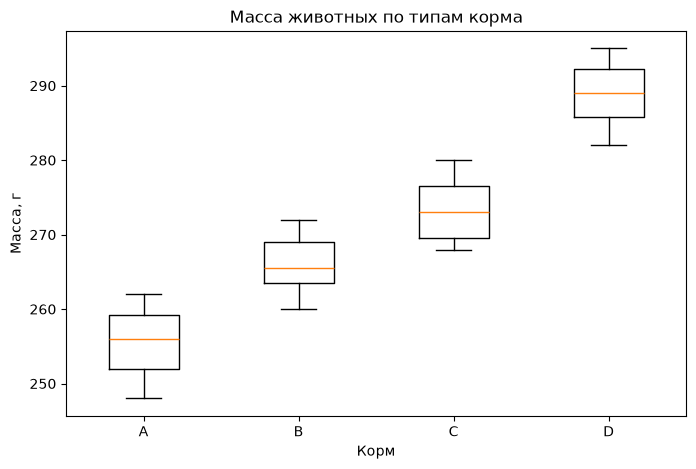

Шапиро A: p-value = 0.8799043359410206
Шапиро B: p-value = 0.9168497282343313
Шапиро C: p-value = 0.6487505294379153
Шапиро D: p-value = 0.941526289387991
Левен p-value = 0.9416944490182294
ANOVA F = 49.924617196702066, p-value = 1.7997252435897232e-09
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     A      B     10.5 0.0064  2.6524 18.3476   True
     A      C  17.8333    0.0  9.9858 25.6809   True
     A      D  33.3333    0.0 25.4858 41.1809   True
     B      C   7.3333 0.0723 -0.5142 15.1809  False
     B      D  22.8333    0.0 14.9858 30.6809   True
     C      D     15.5 0.0001  7.6524 23.3476   True
----------------------------------------------------


In [29]:
A = [251,262,248,255,260,257]
B = [263,270,265,272,260,266]
C = [268,275,271,280,277,269]
D = [282,290,285,295,288,293]

groups = [A, B, C, D]
names = ['A', 'B', 'C', 'D']
alpha = 0.05

plt.figure(figsize=(8, 5))
plt.boxplot(groups, tick_labels=names)
plt.title('Масса животных по типам корма')
plt.xlabel('Корм')
plt.ylabel('Масса, г')
plt.show()

for name, group in zip(names, groups):
    print(f'Шапиро {name}: p-value = {stats.shapiro(group).pvalue}')
lev_stat, lev_p = stats.levene(*groups)
f_stat, anova_p = stats.f_oneway(*groups)
print(f'Левен p-value = {lev_p}')
print(f'ANOVA F = {f_stat}, p-value = {anova_p}')
if anova_p < alpha:
    values = np.concatenate(groups)
    labels = np.repeat(names, [len(group) for group in groups])
    tukey = pairwise_tukeyhsd(values, labels, alpha=alpha)
    print(tukey)

**Вывод:** все данные распределены нормально по тесту Шапиро, по тесту Левена разницы статистической между дисперсиями нет, по ANOVA разница статистическая между средними есть.
По тесту Тьюки видно, что между кормами B и C статистической разницы нет, а D является самым эффективным, градация такая А < B C < D

### Задание 6. A/B-тест по конверсии

Проводится A/B-тест на лендинге. В контрольной группе из 1000 пользователей конверсий 85, в тестовой группе из 1000 пользователей конверсий 120.

**Что сделать:**
- постройте 95% доверительные интервалы Уилсона для конверсии каждой группы;
- проверьте, значимо ли различаются конверсии (критерий хи-квадрат на таблице 2x2 или z-тест для двух долей) при $\alpha = 0.05$;
- постройте бутстрэп-интервал для разности конверсий (тест минус контроль);
- сделайте вывод, стоит ли выкатывать тестовый вариант.

**Выведите на экран:** границы интервалов Уилсона по группам, статистику и p-value выбранного теста, границы бутстрэп-интервала для разности и точечную разность конверсий.

In [30]:
conv_c, n_c = 85, 1000     # контроль
conv_v, n_v = 120, 1000    # тест

alpha = 0.05
dov_c = proportion_confint(conv_c, n_c, alpha=alpha, method='wilson')
dov_v = proportion_confint(conv_v, n_v, alpha=alpha, method='wilson')
print(f'95% доверительный интервал Уилсона контроль = {dov_c}')
print(f'95% доверительный интервал Уилсона тест = {dov_v}')
z, pvalue = proportions_ztest([conv_v, conv_c], [n_v, n_c])
print(f'z = {z}')
print(f'p-value = {pvalue}')
diff = conv_v / n_v - conv_c / n_c
print(f'Разность конверсий = {diff}')
np.random.seed(42)
data_c = np.array([1] * conv_c + [0] * (n_c - conv_c))
data_v = np.array([1] * conv_v + [0] * (n_v - conv_v))
boots = []
for _ in range(10000):
    idx_c = np.random.randint(0, n_c, n_c)
    idx_v = np.random.randint(0, n_v, n_v)
    boots.append(np.mean(data_v[idx_v]) - np.mean(data_c[idx_c]))
dovdown, dovup = np.percentile(boots, [2.5, 97.5])
print(f'95% бутстрэп-интервал = ({dovdown}, {dovup})')

95% доверительный интервал Уилсона контроль = (0.06926331853965456, 0.10391289100335621)
95% доверительный интервал Уилсона тест = (0.10129926060130912, 0.14160907584771276)
z = 2.5803218810023396
p-value = 0.009870826252855024
Разность конверсий = 0.03499999999999999
95% бутстрэп-интервал = (0.008000000000000007, 0.061999999999999986)


**Вывод:** конверсия тестовой группы выше контрольной на 3.5п.п. По z-тесту p-value меньше 0.05, значит разница статистически значимая.
Бутстрэп-интервал от 0.008 до 0.062 не включает 0, что подтверждает результат. По интервалам Уилсона видно, что конверсия тестовой группы выше
Поэтому тестовый вариант можно выкатывать.